# 05 - Modèles spécifiques : posture, locomotion, activités

**Motivation** (cf notebook 01) : les labels de `Behavior_1` ne sont pas exclusifs. On entraîne un modèle
par famille, dont les classes s'excluent mutuellement :

| Famille | Classes |
|---|---|
| posture | Lying chest, Sitting, Standing |
| locomotion | Walking, Trotting, Pacing, Galloping, Jumping |
| activité | Sniffing, Eating, Drinking, Playing, Panting, Shaking, Carrying object, Tugging, Bowing |

Le label d'une famille est cherché dans `Behavior_1`, `2` **ou** `3` : un chien qui halète (`Behavior_1`)
tout en étant debout (`Behavior_2`) fournit un exemple de posture « debout ». Les modèles spécifiques
disposent donc d'exemples que le modèle général ne voit pas.

**Comparaison équitable avec le modèle général** : sur les fenêtres de test communes, où le comportement de
la famille est aussi le comportement principal (`Behavior_1`). F1 macro calculé sur les classes de la
famille ; une prédiction du modèle général hors de la famille compte comme une erreur.

Même protocole qu'au notebook 04 (CV groupée, choix par CV, test à la fin) et même jeu de variables que
le modèle général retenu.

In [3]:
import sys
from pathlib import Path

# Racine du projet ajoutée au chemin d'import (le notebook est dans notebooks/)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src import config as cfg
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

import json
from src import data, features, labels, modeling, evaluation, viz

In [4]:
windows = data.load_table(cfg.WINDOWS_FILE)
dogs = data.load_dogs()
train_ids, test_ids = data.load_split()

pointeur = json.loads((cfg.TABLES_DIR / "meilleur_modele_general.json").read_text())
general = modeling.load_bundle(**pointeur)
pred_general = data.load_table(cfg.PROCESSED_DIR / "predictions_test_general.parquet")
FEATURES = general["features"]
print(f"Modèle général de référence : {general['model_name']} / {general['experiment']} ({len(FEATURES)} variables)")

Modèle général de référence : XGBoost / multi_echelle (282 variables)


In [6]:
MODELES = None   # None = tous ; ex. ["Dummy_majoritaire", "RandomForest", "XGBoost"]

comparaisons, resumes, details = [], [], {}
for fam in cfg.FAMILIES:
    print(f"\n========== {fam.upper()} ==========")
    task = labels.select_task_windows(windows, fam, min_purity=cfg.MIN_PURITY)
    task = task.merge(dogs[["DogID"] + cfg.STATIC_FEATURES], on="DogID", how="left")
    tr_all, te_all = task[task["DogID"].isin(train_ids)], task[task["DogID"].isin(test_ids)]
    tr, te, classes, table = labels.filter_rare_classes(tr_all, te_all, min_count=cfg.MIN_WINDOWS_PER_CLASS)
    display(table)
    if len(classes) < 2:
        print("Moins de deux classes conservées : famille ignorée.")
        continue
    resume, b = modeling.run_experiment(tr, FEATURES, experiment=general["experiment"], task=fam, models=MODELES)
    resumes.append(resume)
    best = modeling.best_bundle(b)
    pred, _ = modeling.predict(best, te)
    res = te[["window_id", "DogID", "target", "behavior_1"]].copy()
    res["pred"] = pred
    details[fam] = (res, classes, best)
    metr = evaluation.compute_metrics(res["target"], res["pred"], labels=classes)
    comp = evaluation.compare_general_specific(pred_general, res, classes)
    comparaisons.append({"famille": fam, "modele_specifique": best["model_name"],
                         "f1_macro_cv_specifique": best["cv_mean"],
                         "f1_macro_test_specifique_toutes_fenetres": metr["f1_macro"], **comp})

resultats_cv = pd.concat(resumes, ignore_index=True)
resultats_cv.to_csv(cfg.TABLES_DIR / "05_resultats_cv_specifiques.csv", index=False)
comparaison = pd.DataFrame(comparaisons)
comparaison.to_csv(cfg.TABLES_DIR / "05_comparaison_general_specifique.csv", index=False)
display(resultats_cv.drop(columns=["meilleurs_params"]).round(3))


========== POSTURE ==========


,n_fenetres_train,n_fenetres_test,conservee
target,,,
Lying chest,17274,4972,True
Sitting,17043,4828,True
Standing,15074,4516,True


[multi_echelle] Dummy_majoritaire ... F1 macro CV = 0.173 ± 0.004 (2.9 s)
[multi_echelle] Dummy_stratifie ... F1 macro CV = 0.335 ± 0.004 (2.0 s)
[multi_echelle] LogisticRegression ... F1 macro CV = 0.783 ± 0.032 (54.1 s)
[multi_echelle] RandomForest ... F1 macro CV = 0.767 ± 0.066 (232.4 s)
[multi_echelle] XGBoost ... F1 macro CV = 0.774 ± 0.040 (96.8 s)


c:\Users\Cours APT\anaconda3\envs\chiens-ml\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")



========== LOCOMOTION ==========


...


========== ACTIVITE ==========


,n_fenetres_train,n_fenetres_test,conservee
target,,,
Panting,26355,6330,True
Sniffing,15065,4165,True
Playing,13717,4231,True
Eating,3952,522,True
Drinking,740,431,True
Shaking,351,141,False
Carrying object,177,9,False
Tugging,18,0,False
Bowing,1,0,False


[multi_echelle] Dummy_majoritaire ... F1 macro CV = 0.122 ± 0.007 (0.3 s)
[multi_echelle] Dummy_stratifie ... F1 macro CV = 0.200 ± 0.003 (0.3 s)
[multi_echelle] LogisticRegression ... F1 macro CV = 0.910 ± 0.021 (72.9 s)
[multi_echelle] RandomForest ... F1 macro CV = 0.929 ± 0.021 (380.5 s)
[multi_echelle] XGBoost ... F1 macro CV = 0.937 ± 0.024 (213.5 s)


c:\Users\Cours APT\anaconda3\envs\chiens-ml\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,experience,tache,modele,f1_macro_cv_moy,f1_macro_cv_std,f1_macro_train_moy,n_variables,n_variables_retenues,duree_s
0,multi_echelle,posture,LogisticRegression,0.783,0.032,0.837,282,55,54.1
1,multi_echelle,posture,XGBoost,0.774,0.040,0.980,282,55,96.8
2,multi_echelle,posture,RandomForest,0.767,0.066,0.997,282,55,232.4
3,multi_echelle,posture,Dummy_stratifie,0.335,0.004,0.334,282,282,2.0
4,multi_echelle,posture,Dummy_majoritaire,0.173,0.004,0.173,282,282,2.9
5,multi_echelle,locomotion,XGBoost,0.827,0.032,1.000,282,64,82.1
6,multi_echelle,locomotion,LogisticRegression,0.816,0.035,0.902,282,64,19.4
7,multi_echelle,locomotion,RandomForest,0.788,0.022,0.986,282,64,96.3
8,multi_echelle,locomotion,Dummy_stratifie,0.253,0.005,0.248,282,282,0.2
9,multi_echelle,locomotion,Dummy_majoritaire,0.155,0.003,0.155,282,282,0.2


Les messages d'erreurs précédents durant les entraînements n'altèrent pas les résultats et sont liés au faible nombre d'individus de notre jeu de données.

## Comparaison général / spécifique

,famille,modele_specifique,f1_macro_cv_specifique,f1_macro_test_specifique_toutes_fenetres,n_fenetres_communes,classes_evaluees,f1_macro_general,exactitude_general,f1_macro_specifique,exactitude_specifique,n_fenetres_specifique_total,part_couverte_seulement_par_specifique
0,posture,LogisticRegression,0.783,0.825,10051,"Lying chest, Sitting, Standing",0.751,0.685,0.801,0.803,14316,0.298
1,locomotion,XGBoost,0.827,0.897,6235,"Trotting, Walking, Pacing",0.845,0.932,0.872,0.960,6984,0.107
2,activite,XGBoost,0.937,0.892,11367,"Panting, Sniffing, Playing, Eating, Drinking",0.776,0.810,0.867,0.958,15679,0.275


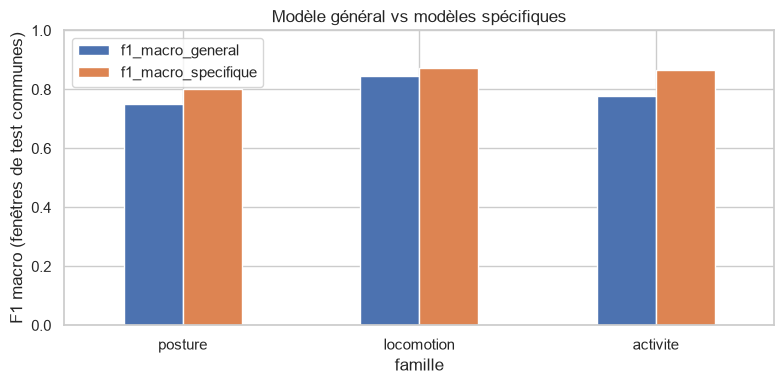

In [7]:
display(comparaison.round(3))
fig, ax = plt.subplots(figsize=(8, 4))
comparaison.set_index("famille")[["f1_macro_general", "f1_macro_specifique"]].plot.bar(ax=ax)
ax.set_ylim(0, 1); ax.set_ylabel("F1 macro (fenêtres de test communes)")
ax.set_title("Modèle général vs modèles spécifiques"); plt.xticks(rotation=0)
plt.tight_layout(); viz.savefig(fig, "05_general_vs_specifique"); plt.show()

Les modèles spécifiques gagnent systématiquement face aux modèles généraux. De plus, le meilleur modèle spécifique de la posture est une régression logistique. Attention cependant pour l'interprétation des résultats : on a limité l'étude des performances des modèles généraux sur une partie du set de test seulement.

## Matrices de confusion des modèles spécifiques

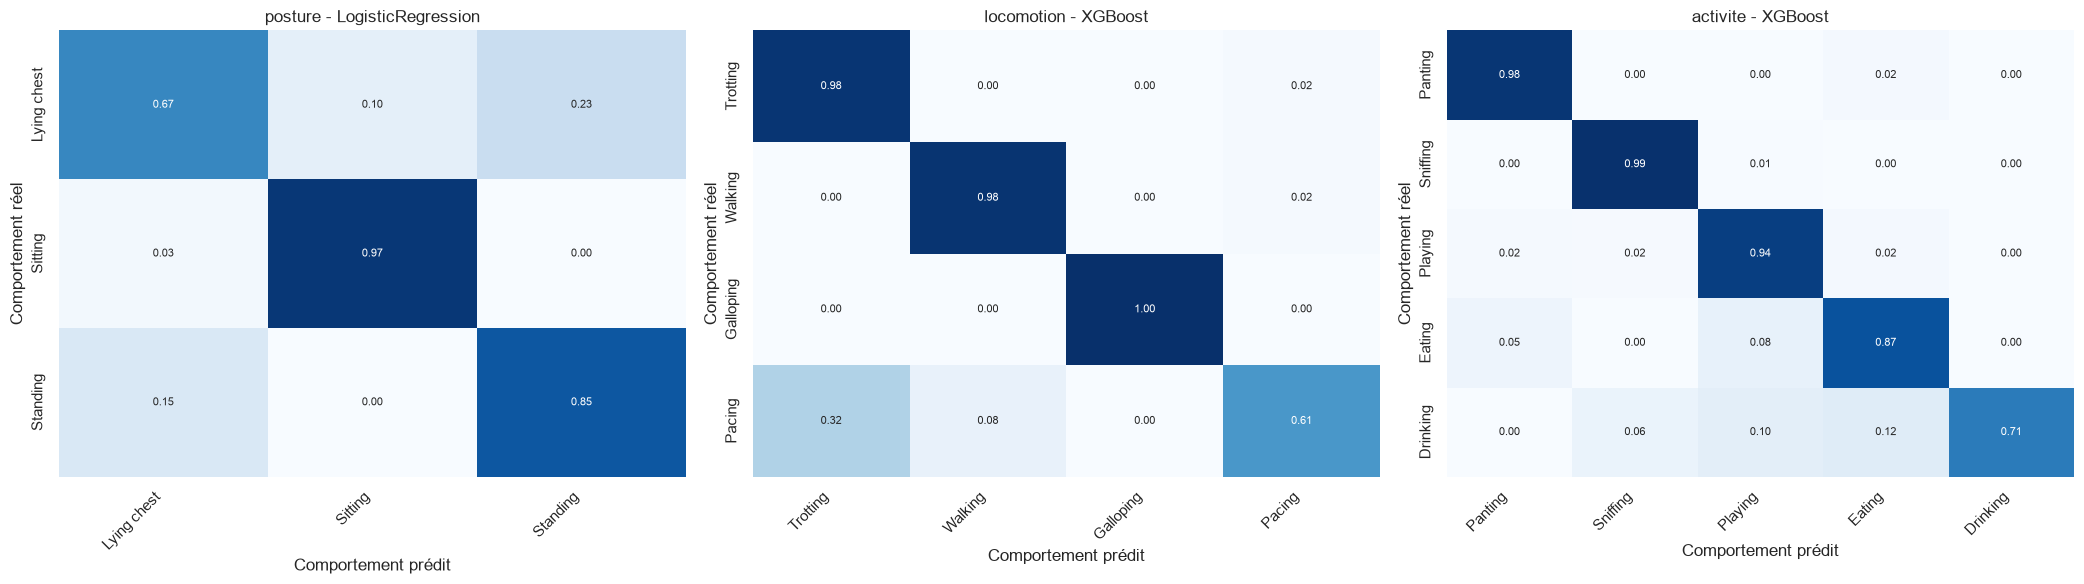

In [5]:
fig, axes = plt.subplots(1, len(details), figsize=(7 * len(details), 6))
for ax, (fam, (res, classes, best)) in zip(np.atleast_1d(axes), details.items()):
    evaluation.plot_confusion(res["target"], res["pred"], classes, ax=ax, title=f"{fam} - {best['model_name']}")
plt.tight_layout(); viz.savefig(fig, "05_confusions_specifiques"); plt.show()